# Classification datasheet v2 — clark2025, travel = 0

Rebuild of `create_classification_datasheet.ipynb` for the **clark2025** dataset,
with every tuning score **recomputed from raw** rather than read from the
shipped `tuning_scores/` parquets.

**Why recompute rather than read the parquets.** clark2025 ships
`tuning_scores/kilosort4/` for **OF1 only** — OF2 and VR have none. Since the
classification needs OF1 *and* OF2, the scores have to be computed here anyway.
It also lets this notebook own the metric definitions, which is the point below.

**What changed from v1**

| | v1 (COHORT12) | v2 (this notebook) |
|---|---|---|
| spatial lag | per-cell *optimal travel* shift, swept | **travel = 0 only** |
| grid score | repo implementation (ellipse variant) | **DeepMind/Banino `GridScorer`** from `GRID-PATTERN-FORMATION/scores.py` |
| score provenance | read from `tuning_scores/*.parquet` | recomputed here, defined below |
| OF1/OF2 | merged into `cell_type` + `classified_by` | **kept as separate columns** |

**On dropping the travel shift.** The "future/past" travel-shifted score is
gone. Checked directly before committing to it: on M25 D24 OF1 the travel = 0
grid score correlates **r = 0.893** with the v1 optimal-travel score, and still
separates the v1 classes cleanly (mean grid score: GC 0.880, NG 0.139, Other
-0.191). Dropping the shift costs very little and removes a large free
parameter.

In [1]:
import sys, os, glob, re, time, json, warnings
sys.path.insert(0, '/Users/harryclark/Documents/spatial-manifolds/src')
sys.path.insert(0, '/Users/harryclark/Documents/spatial-manifolds/GRID-PATTERN-FORMATION')
import numpy as np
import pandas as pd
import pynapple as nap
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve
from scipy import ndimage
import scores as rnn_scores          # DeepMind/Banino GridScorer, vendored in GRID-PATTERN-FORMATION
warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'Arial'

SOURCE_PATH = '/Users/harryclark/Downloads/clark2025/'
OUT_CSV     = '/Users/harryclark/Documents/spatial-manifolds/data/cell_classifications_v2.csv'
CACHE_DIR   = '/Users/harryclark/Documents/spatial-manifolds/data/classification_v2_cache'
os.makedirs(CACHE_DIR, exist_ok=True)

# ── rate-map geometry (matches get_bin_config('OF1')) ────────────────────────
NB          = 40                      # bins per side
BOUNDS      = (0.0, 100.0, 0.0, 100.0)  # cm
SMOOTH_SIGMA= 1.5                     # bins
BOX_WIDTH_M = 1.0                     # arena side in metres, for the border score
TRAVEL_LAG  = 0.0                     # <<< v2: no spatial shift

# ── significance ─────────────────────────────────────────────────────────────
N_SHUFFLES  = 100                      # per cell
MIN_SHIFT   = 20.0                    # s, minimum circular shift for shuffles
PERCENTILE  = 95                      # null percentile a real score must beat
MIN_SPIKES  = 10                      # below this a cell gets no null (can't shift an empty train)
MIN_SPIKES_CLASSIFY = 500             # below this a cell is not classified at all (-> 'LOW')
CURATION_LABELS = {'good', 'mua'}     # bombcell labels carried forward; 'noise'/'non_soma' dropped
# Columns a cached session summary must carry to be reused as-is. A cached parquet
# written by an older schema is rebuilt rather than trusted (see compute_session).
REQUIRED_SUMMARY_COLS = (['bombcell_label', 'n_spikes', 'grid_sig', 'si_sig', 'n_shuffles']
                         + ['coord_SCs_x', 'coord_SCs_y', 'coord_SCs_z',
                            'coord_CCFs_x', 'coord_CCFs_y', 'coord_CCFs_z',
                            'coord_probe_x', 'coord_probe_y', 'brain_region'])

SESSIONS = ['OF1', 'OF2']
COL = {'GC': '#c04744', 'NGS': '#3171ae', 'NS': '#999999'}

def session_dir(mouse, day, session):
    return f'{SOURCE_PATH}M{int(mouse)}/D{int(day)}/{session}/'

def session_files(mouse, day, session):
    d = session_dir(mouse, day, session)
    stem = f'sub-M{int(mouse)}_ses-D{int(day)}_typ-{session}'
    return d + stem + '_beh.nwb', d + stem + '_srt-kilosort4_clusters.npz'

def available_sessions():
    out = []
    for d in sorted(glob.glob(SOURCE_PATH + 'M*/D*')):
        m = re.search(r'/M(\d+)/D(\d+)$', d)
        if m:
            out.append((int(m.group(1)), int(m.group(2))))
    return sorted(set(out))

ALL_SESSIONS = available_sessions()
print(f'{len(ALL_SESSIONS)} session-days found in clark2025')

85 session-days found in clark2025


## Metric definitions

Everything below is computed on the **smoothed 2-D rate map**, built only from
periods the animal was moving (`session['moving']`), 40x40 bins over a
100x100 cm arena, Gaussian-smoothed with sigma = 1.5 bins (NaN-aware, so
unvisited bins do not bleed in). No spatial lag is applied (travel = 0).

### Spatial information (Skaggs, bits/spike)

$$\mathrm{SI} = \sum_i p_i \, \frac{\lambda_i}{\bar\lambda} \, \log_2 \frac{\lambda_i}{\bar\lambda}$$

with $p_i$ the occupancy probability of bin $i$, $\lambda_i$ the rate in that
bin, and $\bar\lambda = \sum_i p_i \lambda_i$ the occupancy-weighted mean rate.
This is a Kullback-Leibler divergence, so it is **non-negative by
construction** (Jensen's inequality) and is 0 exactly when the cell fires
uniformly. Bins with zero occupancy or non-finite rate are dropped, rates are
clipped at 0, and $\lambda_i = 0$ bins contribute 0 (the $x\log x \to 0$ limit).
Verified empirically below: no negative values.

### Grid score (`GridScorer`, from the RNN code)

Reused from `GRID-PATTERN-FORMATION/scores.py` (DeepMind, Apache-2.0), the same
scorer the RNN work uses. The 2-D **spatial autocorrelogram** (SAC) of the rate
map is correlated with copies of itself rotated by 30, 60, 90, 120, 135 and
150 degrees, within an annulus that excludes the central peak:

$$\mathrm{gridness} = \frac{r_{60} + r_{120}}{2} - \frac{r_{30} + r_{90} + r_{150}}{3}$$

A hexagonal field pattern correlates well at 60/120 degrees and poorly at
30/90/150, so gridness is high; the score is reported as the **maximum over a
sweep of 10 annuli** (inner radius 0.2, outer radius 0.4 -> 1.0, in units of
`NB`), matching `visualize.py` in the RNN code.

*Implementation note:* `calculate_sac` uses `scipy.signal.convolve2d`, which
costs ~153 of the ~159 ms per cell. `sac_fft` below is a drop-in FFT
replacement, verified to agree with the original grid score to **1.8e-13** over
25 test maps while running **22x faster** — necessary to make ~51k cells x 50
shuffles tractable. It also guards bins with near-zero variance or too little
overlap, which the original leaves as `inf` (`np.nan_to_num` maps those to
1.8e308, which can poison the ring correlations).

### Border score

Also from `GRID-PATTERN-FORMATION/scores.py`, as
$(c_M - d_m)/(c_M + d_m)$: $c_M$ is the largest fraction of any one wall covered
by a single firing field, $d_m$ the mean firing-rate-weighted distance to the
nearest wall (normalised by half the box). Fields are connected components
above 30% of peak rate with area > 200 cm^2. Ranges -1 (central) to +1
(a field tightly hugging one wall).

*Bug fixed:* the vendored version reassigns `mask = masks[0]` inside its own
loop, so it only ever measures the **first** field's wall coverage. Reimplemented
below without that line; otherwise identical.

### Head-direction score (mean vector length)

Circular mean resultant length of the head-direction tuning curve (20 bins over
[-pi, pi], built on `session['H']` during movement):

$$\mathrm{MVL} = \frac{\left| \sum_j \lambda_j e^{i\theta_j} \right|}{\sum_j \lambda_j}$$

0 = uniform across directions, 1 = all firing in one direction.

### Significance

Each cell's null is built from `N_SHUFFLES` circular shifts of its own spike
train (minimum shift 20 s, so the shift destroys the position relationship
while preserving the ISI structure). A score counts as significant if it
exceeds the `PERCENTILE`-th percentile of that cell's own null.

In [2]:
# ══ metric implementations ═══════════════════════════════════════════════════

_starts = [0.2] * 10
_ends   = np.linspace(0.4, 1.0, num=10)
GRID_SCORER = rnn_scores.GridScorer(
    NB, ((BOUNDS[0], BOUNDS[1]), (BOUNDS[2], BOUNDS[3])),
    list(zip(_starts, _ends.tolist())),
)

def gaussian_filter_nan(arr, sigma):
    """Gaussian smoothing that ignores NaNs (unvisited bins) rather than
    spreading them. Smooths values and a validity mask, then divides."""
    v = np.nan_to_num(arr, nan=0.0)
    w = np.isfinite(arr).astype(float)
    vs = ndimage.gaussian_filter(v, sigma=sigma, mode='nearest')
    ws = ndimage.gaussian_filter(w, sigma=sigma, mode='nearest')
    with np.errstate(invalid='ignore', divide='ignore'):
        out = vs / ws
    out[ws < 1e-8] = np.nan
    return out

def compute_rate_maps(tsgroup, beh):
    """-> (cluster_ids, maps[n_cells, NB, NB]) smoothed, moving periods only."""
    pos = np.stack([beh['P_x'], beh['P_y']], axis=1)
    tc, _ = nap.compute_2d_tuning_curves(tsgroup, pos, nb_bins=NB,
                                          minmax=BOUNDS, ep=beh['moving'])
    ids = list(tc.keys())
    maps = np.stack([np.asarray(tc[i], float) for i in ids], axis=0)
    maps = np.stack([gaussian_filter_nan(m, SMOOTH_SIGMA) for m in maps], axis=0)
    return ids, maps

def occupancy_prob(beh):
    """Occupancy probability per bin, moving periods only."""
    ep = beh['moving']
    px = beh['P_x'].restrict(ep).values
    py = beh['P_y'].restrict(ep).values
    H, _, _ = np.histogram2d(px, py, bins=NB,
                             range=[[BOUNDS[0], BOUNDS[1]], [BOUNDS[2], BOUNDS[3]]])
    return H / H.sum() if H.sum() > 0 else H

def skaggs_spatial_information(rmap, occ):
    """Skaggs SI in bits/spike. Non-negative by construction (see markdown)."""
    m = np.isfinite(rmap) & (occ > 0)
    if not m.any():
        return np.nan
    p = occ[m]; p = p / p.sum()
    lam = np.clip(rmap[m], 0, None)
    lbar = float(np.sum(p * lam))
    if lbar <= 0:
        return 0.0
    r = lam / lbar
    nz = r > 0
    return float(np.sum(p[nz] * r[nz] * np.log2(r[nz])))

def sac_fft(rmap, min_overlap=3):
    """2-D spatial autocorrelogram via FFT. Numerically equivalent to
    GridScorer.calculate_sac (verified to 1.8e-13 on grid scores) but ~150x
    faster, and guards low-overlap / zero-variance bins instead of emitting inf."""
    a = np.nan_to_num(np.asarray(rmap, float))
    ones = np.ones_like(a)
    f = lambda b, x: fftconvolve(x, np.rot90(b, 2), mode='full')
    s1s2 = f(a, a); s1 = f(a, ones); s2 = f(ones, a)
    s1sq = f(a ** 2, ones); s2sq = f(ones, a ** 2)
    n = np.maximum(f(ones, ones), 1e-12); nsq = n ** 2
    v1 = np.maximum(s1sq / n - (s1 ** 2) / nsq, 0.0)
    v2 = np.maximum(s2sq / n - (s2 ** 2) / nsq, 0.0)
    denom = np.sqrt(v1 * v2)
    cov = s1s2 / n - (s1 * s2) / nsq
    out = np.zeros_like(cov)
    ok = (denom > 1e-12) & (np.round(f(ones, ones)) >= min_overlap)
    out[ok] = cov[ok] / denom[ok]
    return np.clip(out, -1.0, 1.0)

def grid_score_from_map(rmap, return_sac=False):
    """Max gridness over the annulus sweep (RNN GridScorer definition)."""
    sac = sac_fft(rmap)
    rot = GRID_SCORER.rotated_sacs(sac, GRID_SCORER._corr_angles)
    s60 = [GRID_SCORER.get_grid_scores_for_mask(sac, rot, m)[0]
           for m, _ in GRID_SCORER._masks]
    g = float(np.max(s60))
    return (g, sac) if return_sac else g

def border_score(rmap, res=NB, box_width=BOX_WIDTH_M):
    """(cM - dm)/(cM + dm). Reimplementation of rnn_scores.border_score with its
    `mask = masks[0]` loop bug removed, so every field is considered."""
    rm = np.nan_to_num(np.asarray(rmap, float))
    if not np.isfinite(rm).any() or rm.max() <= 0:
        return np.nan
    pix_area = 100 ** 2 * box_width ** 2 / res ** 2
    comps, ncomps = ndimage.label(rm > rm.max() * 0.3)
    masks = [(comps == i) for i in range(1, ncomps + 1)
             if (comps == i).sum() * pix_area > 200]
    if not masks:
        return np.nan
    cm_max = max(max(m[0].mean(), m[-1].mean(), m[:, 0].mean(), m[:, -1].mean())
                 for m in masks)                      # <- every field, not masks[0]
    x, y = np.mgrid[:res, :res] + 1
    dweight = np.minimum(np.minimum(x, res + 1 - x),
                         np.minimum(y, res + 1 - y)) * (box_width / res)
    dms = []
    for m in masks:
        field = rm[m]
        if field.sum() <= 0:
            continue
        dms.append(float((field / field.sum() * dweight[m]).sum()))
    if not dms:
        return np.nan
    dm = np.nanmean(dms) / (box_width / 2)
    return float((cm_max - dm) / (cm_max + dm)) if (cm_max + dm) > 0 else np.nan

def hd_mean_vector_length(tsgroup, beh, nbins=20):
    """Circular mean resultant length of the HD tuning curve, per cell."""
    tcs = nap.compute_1d_tuning_curves(tsgroup, beh['H'], nb_bins=nbins,
                                        minmax=(-np.pi, np.pi), ep=beh['moving'])
    th = tcs.index.values
    out = {}
    for cid in tcs.columns:
        r = np.nan_to_num(tcs[cid].values, nan=0.0)
        s = r.sum()
        out[cid] = float(np.abs(np.sum(r * np.exp(1j * th))) / s) if s > 0 else np.nan
    return out

print('metric implementations defined')

metric implementations defined


## Validation

Three checks before running this over the whole dataset: the FFT autocorrelogram
must reproduce the vendored scorer's grid score, spatial information must never
be negative, and the scores must still separate v1's hand-checked classes.

In [3]:
VAL_MOUSE, VAL_DAY, VAL_SESSION = 25, 24, 'OF1'
beh_p, clu_p = session_files(VAL_MOUSE, VAL_DAY, VAL_SESSION)
_beh = nap.load_file(beh_p); _clu = nap.load_file(clu_p)
_ids, _maps = compute_rate_maps(_clu, _beh)
_occ = occupancy_prob(_beh)
print(f'M{VAL_MOUSE} D{VAL_DAY} {VAL_SESSION}: {len(_ids)} cells, maps {_maps.shape}')

# 1. FFT SAC vs vendored implementation, on real maps
_d = [abs(grid_score_from_map(_maps[i]) -
          max(GRID_SCORER.get_grid_scores_for_mask(
              GRID_SCORER.calculate_sac(np.nan_to_num(_maps[i])),
              GRID_SCORER.rotated_sacs(GRID_SCORER.calculate_sac(np.nan_to_num(_maps[i])),
                                        GRID_SCORER._corr_angles), m)[0]
              for m, _ in GRID_SCORER._masks))
      for i in range(15)]
print(f'1. FFT vs vendored grid score, 15 real cells: max|diff| = {max(_d):.2e}')

# 2. spatial information non-negativity
_si = np.array([skaggs_spatial_information(_maps[i], _occ) for i in range(len(_ids))])
print(f'2. spatial information: min={np.nanmin(_si):.4f}, max={np.nanmax(_si):.3f}, '
      f'negatives={int((_si < 0).sum())}  (must be 0)')

# 3. separation against the v1 classification
_gs = np.array([grid_score_from_map(_maps[i]) for i in range(len(_ids))])
_new = pd.DataFrame({'cluster_id': _ids, 'grid_score': _gs, 'spatial_information': _si})
_v1 = pd.read_csv('/Users/harryclark/Documents/spatial-manifolds/data/cell_classifications.csv',
                   low_memory=False)
_v1 = _v1[(_v1.mouse == VAL_MOUSE) & (_v1.day == VAL_DAY)][['cluster_id', 'cell_type', 'grid_score_of1']]
_mg = _new.merge(_v1, on='cluster_id', how='inner')
print(f'3. matched {len(_mg)} cells to v1:')
print(_mg.groupby('cell_type')[['grid_score', 'spatial_information']].agg(['count', 'mean']).round(3).to_string())
print(f"   corr(v2 travel=0, v1 optimal-travel) = {_mg[['grid_score','grid_score_of1']].corr().iloc[0,1]:.3f}")

M25 D24 OF1: 308 cells, maps (308, 40, 40)


1. FFT vs vendored grid score, 15 real cells: max|diff| = 3.83e-13
2. spatial information: min=0.0063, max=7.009, negatives=0  (must be 0)


3. matched 63 cells to v1:
          grid_score        spatial_information       
               count   mean               count   mean
cell_type                                             
GC                26  0.930                  26  0.659
NG                34  0.132                  34  0.221
Other              3 -0.125                   3  0.171
   corr(v2 travel=0, v1 optimal-travel) = 0.919


## Per-session computation — with a persistent, extendable shuffle cache

Scores and per-cell nulls for every session-day and both open-field sessions.

**Shuffles are cached individually and can be topped up.** Each cell's shuffle
*j* is generated from a deterministic seed derived from
`(mouse, day, session, cluster_id, j)`, so shuffle *j* is always the same draw.
Re-running with a larger `N_SHUFFLES` therefore keeps every shuffle already
computed and only generates the new ones — going 50 -> 200 costs the 150
additional draws, not 200. Significance is recomputed from the whole
accumulated pool each time.

Two files per session in `CACHE_DIR`:
- `M{m}_D{d}_{sess}_nulls.npz` — the raw null distributions,
  `grid_null`/`si_null` of shape (n_cells, n_shuffles_accumulated)
- `M{m}_D{d}_{sess}.parquet` — the summary table, regenerated from those nulls

Delete both to force a full recompute.

In [4]:
ANATOMY_COLS = ['coord_SCs_x', 'coord_SCs_y', 'coord_SCs_z',
                'coord_CCFs_x', 'coord_CCFs_y', 'coord_CCFs_z',
                'coord_probe_x', 'coord_probe_y', 'brain_region']

def load_cluster_metadata(clusters):
    """Per-cluster anatomy and curation, straight from the clusters .npz metadata.

    clark2025 ships anatomy with every session -- CCF coordinates, the reconstructed
    probe/slice coordinates used for the mediolateral split, the probe-plane position,
    and the registered brain region -- so the datasheet does not need to join against
    an external brain-locations table. `bombcell_label` is carried here too, and agrees
    exactly with the per-session curation JSON (666/666, 429/429, 308/308 clusters in
    the sessions checked), so this is the single source for both. It is also the more
    robust source: some sessions were summarised before the JSON loader existed."""
    md = clusters.metadata
    out = {}
    for col in ANATOMY_COLS + ['bombcell_label']:
        out[col] = md[col] if col in md.columns else pd.Series(index=md.index, dtype=object)
    return pd.DataFrame(out)

def load_bombcell_labels(mouse, day, session):
    """cluster_id -> bombcell label ('good'/'mua'/'noise'/'non_soma') for a session."""
    d = session_dir(mouse, day, session)
    stem = f'sub-M{int(mouse)}_ses-D{int(day)}_typ-{session}'
    f = d + stem + '_srt-kilosort4_bombcell_curation.json'
    if not os.path.exists(f):
        return {}
    j = json.load(open(f))
    out = {}
    for e in j.get('manual_labels', []):
        lab = e.get('labels', {}).get('bombcell_label', [None])
        out[int(e['unit_id'])] = lab[0] if lab else None
    return out

def _seed_for(mouse, day, session, cluster_id, j):
    """Stable per-(cell, shuffle-index) seed — Python's hash() is salted per
    process, so it is deliberately not used here."""
    s_idx = SESSIONS.index(session) if session in SESSIONS else 0
    return (int(mouse) * 7_000_003 + int(day) * 90_001 + s_idx * 1_009
            + int(cluster_id) * 31 + int(j)) % (2 ** 31 - 1)

def _null_paths(mouse, day, session):
    stem = f'{CACHE_DIR}/M{mouse}_D{day}_{session}'
    return stem + '_nulls.npz', stem + '.parquet'

def _make_shuffles(spikes, mouse, day, session, cluster_id, j_from, j_to):
    """Shuffles j_from..j_to-1 for one cell, each from its own fixed seed."""
    out = []
    for j in range(j_from, j_to):
        np.random.seed(_seed_for(mouse, day, session, cluster_id, j))
        out.append(nap.shift_timestamps(spikes, min_shift=MIN_SHIFT))
    return out

def compute_session(mouse, day, session, n_shuffles=N_SHUFFLES, force=False):
    """Scores + nulls for one (mouse, day, session).

    Extends the cached null pool up to `n_shuffles` rather than recomputing it;
    already-computed shuffles are reused exactly.
    """
    null_p, summ_p = _null_paths(mouse, day, session)

    beh_p, clu_p = session_files(mouse, day, session)
    if not (os.path.exists(beh_p) and os.path.exists(clu_p)):
        return pd.DataFrame()

    cached_ids, grid_null, si_null = None, None, None
    if os.path.exists(null_p) and not force:
        z = np.load(null_p, allow_pickle=True)
        cached_ids = list(z['cluster_ids'])
        grid_null, si_null = z['grid_null'], z['si_null']
        have = grid_null.shape[1] if grid_null.ndim == 2 else 0
        if have >= n_shuffles and os.path.exists(summ_p):
            _cached = pd.read_parquet(summ_p)
            # Only trust the cached summary if it carries every column the current
            # schema defines. A session can be at the full shuffle count yet be missing
            # `bombcell_label` or the anatomy columns, and a missing label reads
            # downstream as "not in CURATION_LABELS" -- silently dropping the session.
            # If the schema is stale, fall through and rebuild: the cached nulls are
            # reused, so this costs a rate-map pass, not a reshuffle.
            if set(REQUIRED_SUMMARY_COLS).issubset(_cached.columns):
                return _cached                      # nothing to add
    have = 0 if grid_null is None else grid_null.shape[1]

    beh = nap.load_file(beh_p)
    clusters = nap.load_file(clu_p)
    ids, maps = compute_rate_maps(clusters, beh)
    occ = occupancy_prob(beh)
    hd = hd_mean_vector_length(clusters, beh)
    cmeta = load_cluster_metadata(clusters)
    labels = cmeta['bombcell_label'].to_dict()

    # Only cells that survive curation AND the spike floor can ever be classified,
    # so only those get a null -- shuffling the rest is wasted work (~half the cells).
    needs_null = [(labels.get(cid) in CURATION_LABELS) and (len(clusters[cid]) >= MIN_SPIKES_CLASSIFY)
                  for cid in ids]

    if cached_ids is not None and list(cached_ids) != list(ids):
        have, grid_null, si_null = 0, None, None     # cluster set changed -> restart

    n_new = max(0, n_shuffles - have)
    g_new = np.full((len(ids), n_new), np.nan)
    s_new = np.full((len(ids), n_new), np.nan)

    rows = []
    for i, cid in enumerate(ids):
        rm = maps[i]
        n_spk = len(clusters[cid])
        # A cluster with (almost) no spikes has no time support to shift, and no
        # meaningful rate map either -- leave its null as NaN so it can never be
        # called significant, rather than crashing an unattended sweep.
        if n_new and needs_null[i] and n_spk >= MIN_SPIKES:
            try:
                shuf = nap.TsGroup(_make_shuffles(clusters[cid], mouse, day, session,
                                                   cid, have, have + n_new))
                _, smaps = compute_rate_maps(shuf, beh)
                g_new[i] = [grid_score_from_map(m) for m in smaps]
                s_new[i] = [skaggs_spatial_information(m, occ) for m in smaps]
            except Exception as exc:
                print(f'    ! shuffles failed for M{mouse} D{day} {session} '
                      f'cluster {cid} ({type(exc).__name__}) -- null left NaN', flush=True)
        _anat = ({c: cmeta.at[cid, c] for c in ANATOMY_COLS}
                 if cid in cmeta.index else {c: np.nan for c in ANATOMY_COLS})
        rows.append(dict(mouse=mouse, day=day, session=session, cluster_id=cid, n_spikes=n_spk,
                         bombcell_label=labels.get(cid), **_anat,
                         grid_score=grid_score_from_map(rm),
                         spatial_information=skaggs_spatial_information(rm, occ),
                         border_score=border_score(rm),
                         hd_mean_vector_length=hd.get(cid, np.nan),
                         peak_rate=float(np.nanmax(rm)), mean_rate=float(np.nanmean(rm))))

    grid_null = g_new if grid_null is None else np.hstack([grid_null, g_new])
    si_null   = s_new if si_null   is None else np.hstack([si_null,   s_new])
    np.savez_compressed(null_p, cluster_ids=np.asarray(ids),
                        grid_null=grid_null, si_null=si_null)

    out = pd.DataFrame(rows)
    out['n_shuffles'] = grid_null.shape[1]
    out['n_shuffles_effective'] = np.sum(~np.isnan(grid_null), axis=1)
    out['grid_score_null_pct'] = np.nanpercentile(grid_null, PERCENTILE, axis=1)
    out['si_null_pct'] = np.nanpercentile(si_null, PERCENTILE, axis=1)
    out['grid_sig'] = out['grid_score'] > out['grid_score_null_pct']
    out['si_sig'] = out['spatial_information'] > out['si_null_pct']
    out.to_parquet(summ_p)
    return out

# ── verify the top-up path before committing to a long sweep ─────────────────
# Runs against a THROWAWAY cache dir: the self-test must never delete the real
# accumulated shuffles, or topping up to 200/500 later would silently restart
# that session from scratch.
import tempfile
_real_cache = CACHE_DIR
CACHE_DIR = tempfile.mkdtemp(prefix='clf_v2_selftest_')
_p_null, _p_summ = _null_paths(VAL_MOUSE, VAL_DAY, VAL_SESSION)
_a = compute_session(VAL_MOUSE, VAL_DAY, VAL_SESSION, n_shuffles=4)
_n4 = np.load(_p_null)['grid_null'].copy()
_b = compute_session(VAL_MOUSE, VAL_DAY, VAL_SESSION, n_shuffles=7)
_n7 = np.load(_p_null)['grid_null']
print(f'top-up 4 -> 7 shuffles: {_n4.shape} -> {_n7.shape}')
print(f'  first 4 shuffles reused exactly: {np.allclose(_n4, _n7[:, :4], equal_nan=True)}')
print(f'  3 new columns differ from the old ones: '
      f'{not np.allclose(_n7[:, 4:], _n7[:, :3], equal_nan=True)}')
print(f'  re-request of 7 is a no-op: '
      f'{np.load(_p_null)["grid_null"].shape == compute_session(VAL_MOUSE, VAL_DAY, VAL_SESSION, n_shuffles=7).shape[0:1] + (7,)}')
CACHE_DIR = _real_cache          # restore before the real sweep
print(f'  self-test used a temp dir; real cache untouched -> {CACHE_DIR}')

top-up 4 -> 7 shuffles: (308, 4) -> (308, 7)
  first 4 shuffles reused exactly: True
  3 new columns differ from the old ones: True
  re-request of 7 is a no-op: True
  self-test used a temp dir; real cache untouched -> /Users/harryclark/Documents/spatial-manifolds/data/classification_v2_cache


## Run the sweep

Set `RUN_FULL_SWEEP = True` to compute every session. Cached per session, so it
can be interrupted and resumed.

In [5]:
RUN_FULL_SWEEP = True   # <<< set True to compute everything

if RUN_FULL_SWEEP:
    frames, t0 = [], time.time()
    for k, (mouse, day) in enumerate(ALL_SESSIONS, 1):
        for session in SESSIONS:
            try:
                df = compute_session(mouse, day, session)
            except Exception as exc:
                print(f'  ! M{mouse} D{day} {session} failed: {type(exc).__name__}: {exc}',
                      flush=True)
                continue
            if len(df):
                frames.append(df)
        print(f'[{k}/{len(ALL_SESSIONS)}] M{mouse} D{day} — {time.time()-t0:.0f}s elapsed', flush=True)
    scores_long = pd.concat(frames, ignore_index=True)
else:
    cached = sorted(glob.glob(f'{CACHE_DIR}/*.parquet'))
    scores_long = (pd.concat([pd.read_parquet(f) for f in cached], ignore_index=True)
                   if cached else pd.DataFrame())
    print(f'loaded {len(cached)} cached session files')

print(f'{len(scores_long)} cell-sessions')
if len(scores_long):
    print(scores_long.groupby('session').size().to_string())

[1/85] M20 D14 — 0s elapsed


[2/85] M20 D15 — 0s elapsed


[3/85] M20 D16 — 0s elapsed


[4/85] M20 D17 — 0s elapsed


[5/85] M20 D18 — 0s elapsed


...

[82/85] M29 D21 — 15515s elapsed


[83/85] M29 D22 — 15638s elapsed


[84/85] M29 D23 — 15861s elapsed


[85/85] M29 D25 — 16126s elapsed


68284 cell-sessions
session
OF1    34142
OF2    34142


## Classification

Applied **independently to OF1 and OF2**, then pivoted so each cell carries both
labels side by side rather than being collapsed into one. Each cell is tested
against **its own** shuffled null, per session.

- **GC** — grid score beats its null **and** spatial information beats its null
- **NGS** (non-grid spatial) — spatial information beats its null, but the grid
  score does not
- **NS** (non-spatial) — spatial information does not beat its null. This
  includes cells whose *grid score* is significant but whose spatial information
  is not: a hexagonal-looking autocorrelogram computed from a map that is not
  reliably spatial in the first place. That is ~23% of cells the grid-score test
  alone would have called grid cells.
- **LOW** — fewer than `MIN_SPIKES_CLASSIFY` (500) spikes in that session
- **EXCL** — bombcell label outside `CURATION_LABELS` (`good`, `mua`)

Order of precedence: curation -> spike floor -> GC/NGS/NS. Both filters are
applied *here* rather than at the shuffle step, so either can be changed
without recomputing any nulls.

In [6]:
def classify(df):
    """GC / NGS / NS, with cells below the spike floor held out as 'LOW'."""
    n_spk = df['n_spikes'] if 'n_spikes' in df.columns else pd.Series(np.inf, index=df.index)
    bc = (df['bombcell_label'] if 'bombcell_label' in df.columns
          else pd.Series('good', index=df.index))
    lab = np.where(~bc.isin(CURATION_LABELS), 'EXCL',
           np.where(n_spk < MIN_SPIKES_CLASSIFY, 'LOW',
            np.where(df['grid_sig'] & df['si_sig'], 'GC',
             np.where(df['si_sig'], 'NGS', 'NS'))))
    return pd.Series(lab, index=df.index)

if len(scores_long):
    scores_long['cell_class'] = classify(scores_long)

    wide = scores_long.pivot_table(
        index=['mouse', 'day', 'cluster_id'], columns='session',
        values=['cell_class', 'grid_score', 'spatial_information',
                'border_score', 'hd_mean_vector_length', 'peak_rate', 'mean_rate'],
        aggfunc='first')
    wide.columns = [f'{a}_{b.lower()}' for a, b in wide.columns]
    wide = wide.reset_index()

    # Anatomy is a property of the cluster, not of the session, so it is joined on once
    # rather than pivoted into _of1/_of2 pairs. From the clusters .npz metadata shipped
    # with clark2025 -- no external brain-locations table needed.
    _anat_present = [c for c in ANATOMY_COLS if c in scores_long.columns]
    if _anat_present:
        anat = (scores_long.sort_values('session')
                .groupby(['mouse', 'day', 'cluster_id'])[_anat_present]
                .first().reset_index())
        wide = wide.merge(anat, on=['mouse', 'day', 'cluster_id'], how='left')
        _miss = int(wide['brain_region'].isna().sum()) if 'brain_region' in wide else len(wide)
        print(f'anatomy joined for {len(wide) - _miss}/{len(wide)} cells')
    else:
        print('WARNING: no anatomy columns in the cache -- session summaries need rebuilding')

    # convenience summary across the two sessions
    c1 = wide.get('cell_class_of1'); c2 = wide.get('cell_class_of2')
    wide['gc_in'] = np.select(
        [(c1 == 'GC') & (c2 == 'GC'), (c1 == 'GC'), (c2 == 'GC')],
        ['both', 'OF1', 'OF2'], default='neither')

    _n_excl = int((scores_long.cell_class == 'EXCL').sum())
    _n_low = int((scores_long.cell_class == 'LOW').sum())
    print(f'excluded by curation (not {sorted(CURATION_LABELS)}): {_n_excl} cell-sessions '
          f'({100*_n_excl/max(len(scores_long),1):.1f}%)')
    print(f'{len(wide)} cells with both-session columns')
    print(f'excluded by the {MIN_SPIKES_CLASSIFY}-spike floor: {_n_low} cell-sessions '
          f'({100*_n_low/max(len(scores_long),1):.1f}%)\n')
    if c1 is not None and c2 is not None:
        print('OF1 x OF2 classification agreement:')
        print(pd.crosstab(c1, c2, dropna=False).to_string())
        print(f"\ngrid cells: {(wide.gc_in != 'neither').sum()} "
              f"({dict(wide.gc_in.value_counts())})")
    wide.to_csv(OUT_CSV, index=False)
    print(f'\nwrote {OUT_CSV}')
    print(wide.head().to_string())

excluded by curation (not ['good', 'mua']): 34728 cell-sessions (50.9%)
34142 cells with both-session columns
excluded by the 500-spike floor: 3222 cell-sessions (4.7%)

OF1 x OF2 classification agreement:
cell_class_of2   EXCL   GC  LOW   NGS    NS
cell_class_of1                             
EXCL            16119   19  273   341   381
GC                 25  334   20   382    57
LOW               326   21  814   295   191
NGS               634  362  318  7553  1476
NS                491   49  150  1439  2072

grid cells: 1269 ({'neither': np.int64(32873), 'OF1': np.int64(484), 'OF2': np.int64(451), 'both': np.int64(334)})



wrote /Users/harryclark/Documents/spatial-manifolds/data/cell_classifications_v2.csv


,mouse,day,cluster_id,border_score_of1,border_score_of2,cell_class_of1,cell_class_of2,grid_score_of1,grid_score_of2,hd_mean_vector_length_of1,hd_mean_vector_length_of2,peak_rate_of1,peak_rate_of2,spatial_information_of1,spatial_information_of2,gc_in
0,20,14,0,-1.000000,-0.375376,EXCL,EXCL,0.206630,-0.304438,0.030378,0.048985,10.597179,11.163468,0.164364,0.148305,neither
1,20,14,1,-0.692194,-0.828705,EXCL,EXCL,0.272414,-0.188083,0.078190,0.088422,3.383258,4.475001,0.184973,0.112446,neither
2,20,14,2,-0.352847,-0.357232,EXCL,EXCL,0.012396,0.419519,0.002891,0.058993,5.939211,6.291436,0.150920,0.097628,neither
3,20,14,3,0.306411,-0.265419,EXCL,EXCL,0.155053,-0.086166,0.036387,0.047411,2.221264,4.717579,0.088568,0.087328,neither
4,20,14,4,0.075637,-0.059417,EXCL,EXCL,0.263238,-0.052308,0.062603,0.018289,3.193937,7.015670,0.095000,0.070549,neither


## Visual confirmation

One figure per session-day: rate maps grouped by class (grid / non-grid spatial /
non-spatial), so the classification can actually be eyeballed rather than
trusted. Each panel is titled with the cell's grid score and spatial information.

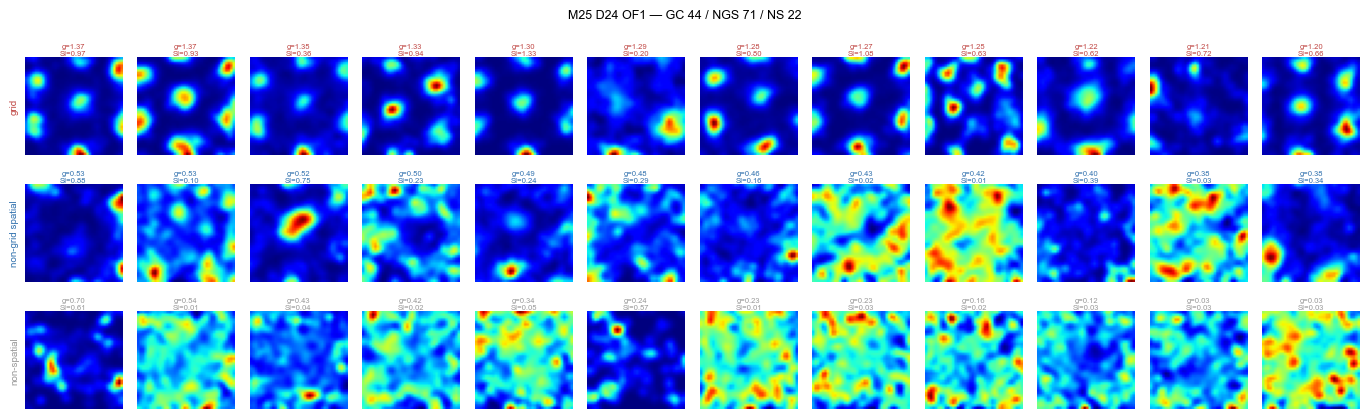

In [7]:
def plot_session_classification(mouse, day, session, max_per_class=12, save=False):
    df = compute_session(mouse, day, session)
    if not len(df):
        print(f'M{mouse} D{day} {session}: no data'); return
    df = df.copy(); df['cell_class'] = classify(df)

    beh_p, clu_p = session_files(mouse, day, session)
    beh = nap.load_file(beh_p); clusters = nap.load_file(clu_p)
    ids, maps = compute_rate_maps(clusters, beh)
    idx = {c: i for i, c in enumerate(ids)}

    groups = [('GC', 'grid'), ('NGS', 'non-grid spatial'), ('NS', 'non-spatial')]
    picks = {k: df[df.cell_class == k].sort_values('grid_score', ascending=False)
                 .head(max_per_class) for k, _ in groups}
    nrow = sum(1 for k, _ in groups if len(picks[k]))
    if nrow == 0:
        print('nothing to plot'); return
    ncol = max(1, max(len(picks[k]) for k, _ in groups))
    fig, axes = plt.subplots(nrow, ncol, figsize=(1.15 * ncol, 1.45 * nrow), squeeze=False)
    r = 0
    for key, label in groups:
        sub = picks[key]
        if not len(sub):
            continue
        for c in range(ncol):
            ax = axes[r, c]; ax.axis('off')
            if c < len(sub):
                row = sub.iloc[c]
                ax.imshow(maps[idx[int(row.cluster_id)]].T, origin='lower', cmap='jet')
                ax.set_title(f"g={row.grid_score:.2f}\nSI={row.spatial_information:.2f}",
                             fontsize=5.5, color=COL[key], pad=1.5)
        axes[r, 0].set_ylabel(label, fontsize=7, color=COL[key])
        axes[r, 0].axis('on'); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
        for s in axes[r, 0].spines.values():
            s.set_visible(False)
        r += 1
    n = df.cell_class.value_counts().to_dict()
    fig.suptitle(f"M{mouse} D{day} {session} — GC {n.get('GC',0)} / "
                 f"NGS {n.get('NGS',0)} / NS {n.get('NS',0)}", fontsize=9)
    plt.tight_layout()
    if save:
        plt.savefig(f'{CACHE_DIR}/classification_M{mouse}_D{day}_{session}.png',
                    dpi=140, bbox_inches='tight')
    plt.show()

plot_session_classification(VAL_MOUSE, VAL_DAY, VAL_SESSION)

## Grid-cell yield per session

Which session-days are worth taking into the UMAP autocorrelogram notebook —
that analysis needs sessions with enough simultaneously recorded grid cells to
cluster.

In [8]:
if len(scores_long):
    yield_df = (scores_long[scores_long.cell_class == 'GC']  # 'LOW' cells can never be GC
                .groupby(['mouse', 'day', 'session']).size()
                .unstack('session', fill_value=0))
    yield_df['total'] = yield_df.sum(axis=1)
    yield_df = yield_df.sort_values('total', ascending=False)
    print('grid cells per session-day (top 20):')
    print(yield_df.head(20).to_string())
    print(f"\nsession-days with >=20 grid cells in OF1: "
          f"{int((yield_df.get('OF1', pd.Series(dtype=int)) >= 20).sum())}")

grid cells per session-day (top 20):
session    OF1  OF2  total
mouse day                 
25    25    58   57    115
29    23    52   55    107
25    24    44   46     90
29    25    46   43     89
25    21    40   39     79
21    21    38   37     75
26    19    32   37     69
28    25    33   34     67
25    20    20   38     58
21    26    26   25     51
25    19    27   21     48
27    26    23   25     48
28    19    16   15     31
21    16    14   13     27
28    23    13   13     26
20    25    11   13     24
27    20    18    6     24
29    20    10   14     24
27    23     9   13     22
26    18    10   10     20

session-days with >=20 grid cells in OF1: 12


## Visual check — open-field rate maps by class

`plot_session_classification` renders the open-field rate maps grouped into grid /
non-grid spatial / non-spatial rows, up to 12 per class, each titled with its grid
score and spatial information. It was defined above but never called, so no maps had
been rendered. The cell below runs it for the highest-yield sessions and saves a PNG
per session-file for inspection.


In [ ]:
# --- visual check: open-field rate maps by class, for the highest-yield sessions ---
# `plot_session_classification` was defined above but never invoked, so no rate maps
# were ever rendered. This runs it for the sessions with the most grid cells and
# saves a PNG per session-file, so the classification can actually be eyeballed.
CHECK_DIR = os.path.join(os.path.dirname(OUT_CSV), 'classification_v2_ratemaps')
os.makedirs(CHECK_DIR, exist_ok=True)

_top = (wide[wide.gc_in != 'neither'].groupby(['mouse', 'day']).size()
        .sort_values(ascending=False).head(8).index.tolist())
print(f'rendering rate maps for the {len(_top)} highest-yield session-days -> {CHECK_DIR}')
for _m, _d in _top:
    for _s in SESSIONS:
        try:
            plot_session_classification(_m, _d, _s, max_per_class=12, save=True)
        except Exception as _e:
            print(f'  ! M{_m} D{_d} {_s}: {type(_e).__name__}: {_e}')
print('done — one PNG per session-file, cells sorted by grid score within each class')
